# Repulsion, birth–death, filtering and spatial uncertainty
We keep posterior particle transport, sequential filtering and shared parameter learning in separate experiments. Repulsive KDE transport uses each particle's own score minus its density estimate's query score. Birth–death adds centered density/energy reactions and ancestry to Langevin transport. [R16](../docs/references.md#r16), [R17](../docs/references.md#r17), [R18](../docs/references.md#r18).

In [1]:
import os, json, time, platform
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lafa import samplers
from lafa.problems import Gaussian, GaussianMixture2D, Banana2D

torch.set_num_threads(1)
device = torch.device(os.environ.get('LAFA_DEVICE', 'cpu'))
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('LAFA_DEVICE=cuda requested, but CUDA is unavailable')
dtype, seed = torch.float64, 2026
quick = os.environ.get('LAFA_QUICK', '1') == '1'
torch.manual_seed(seed)
def gen(offset=0):
    return torch.Generator(device=device).manual_seed(seed + offset)
def tensor(x): return torch.as_tensor(x, device=device, dtype=dtype)
def cpu(x): return x.detach().cpu().numpy()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize(device)
def table(rows):
    keys = list(dict.fromkeys(k for row in rows for k in row))
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
        '\n'.join('| ' + ' | '.join(f'{r[k]:.4g}' if isinstance(r.get(k),float) else str(r.get(k, '—')) for k in keys) + ' |' for r in rows)))
def contour(ax, target, bounds=(-5,5,-5,5)):
    a=torch.linspace(bounds[0],bounds[1],100,device=device,dtype=dtype)
    b=torch.linspace(bounds[2],bounds[3],100,device=device,dtype=dtype)
    xx,yy=torch.meshgrid(a,b,indexing='xy')
    with torch.no_grad(): u=target(torch.stack((xx,yy),-1))
    ax.contour(cpu(xx),cpu(yy),cpu(u-u.min()),levels=[.5,1,2,4,8,16],colors='0.7',linewidths=.6)
    ax.set(xlim=bounds[:2],ylim=bounds[2:]); ax.set_aspect('equal')
def covariance(x):
    z=x-x.mean(0); return z.T@z/(len(x)-1)
def collect(method, steps, burn=0, thin=1):
    samples=[]; trace=[]; hs=[]; accepted=[]
    for i in range(steps):
        r=method.step(); trace.append(r.position.reshape(-1,r.position.shape[-1])[0].clone())
        hs.append(float(torch.as_tensor(r.stats.get('step_size',getattr(method,'step_size',float('nan')))).double().mean()))
        if getattr(r,'accepted',None) is not None: accepted.append(r.accepted.double().mean())
        if i>=burn and (i-burn)%thin==0: samples.append(r.position.reshape(-1,r.position.shape[-1]))
    return torch.cat(samples),torch.stack(trace),hs,float(torch.stack(accepted).mean()) if accepted else float('nan')
root=Path.cwd() if (Path.cwd()/'docs').exists() else Path.cwd().parent
assets=root/'docs'/'assets'; assets.mkdir(parents=True,exist_ok=True)
print(json.dumps(dict(device=str(device),dtype=str(dtype),seed=seed,quick=quick,torch=torch.__version__,python=platform.python_version(),hardware=torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor() or platform.machine())))


{"device": "cpu", "dtype": "torch.float64", "seed": 2026, "quick": true, "torch": "2.6.0+cpu", "python": "3.12.14", "hardware": "x86_64"}


| method | seconds | mean_error | mode0 | mode1 | mode2 | mode3 |
|---|---|---|---|---|---|---|
| KDE repulsive | 0.1133 | 0.9591 | 11 | 5 | 7 | 5 |
| WFR birth–death | 0.654 | 0.7922 | 5 | 10 | 5 | 8 |

Total birth/death events: 35


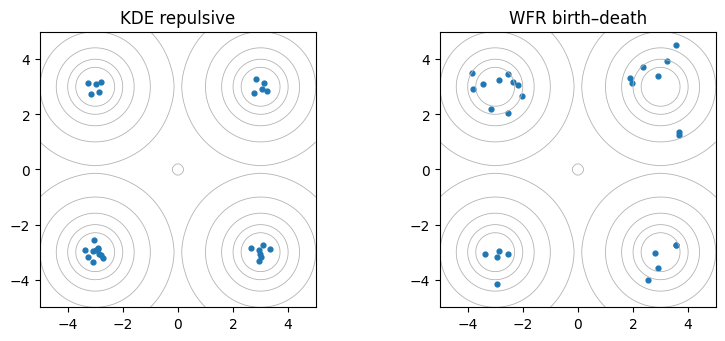

In [2]:
from lafa.particles import RepulsiveEnsemble
from lafa.specialized import BirthDeathLangevin,SALEnKF
from lafa.kernels import RBF
from lafa.problems import LinearGaussianStateSpace,NonlinearTomography2D,quadrature_2d
mix=GaussianMixture2D(device=device,dtype=dtype)
initial=mix.sample(28,generator=gen())+tensor([.3,-.2])
methods={'KDE repulsive':RepulsiveEnsemble(mix,initial,step_size=.04,kernel=RBF(.7)),
 'WFR birth–death':BirthDeathLangevin(mix,initial,.025,bandwidth=.7,generator=gen(1))}
iterations=90 if quick else 300; rows=[]; reaction_count=0
for name,m in methods.items():
    sync(); start=time.perf_counter()
    for _ in range(iterations):
        r=m.step(); reaction_count+=int(r.stats.get('births',0))+int(r.stats.get('deaths',0))
    sync(); labels=(m.position[:,None]-mix.means).square().sum(-1).argmin(-1)
    rows.append(dict(method=name,seconds=time.perf_counter()-start,mean_error=float((m.position.mean(0)-mix.mean).norm()),**{f'mode{k}':int((labels==k).sum()) for k in range(4)}))
table(rows); print('Total birth/death events:',reaction_count)
fig,ax=plt.subplots(1,2,figsize=(8,3.3),layout='constrained')
for a,(name,m) in zip(ax,methods.items()): contour(a,mix); a.scatter(*cpu(m.position).T,s=12); a.set_title(name)
plt.show()

The reaction method preserves population size, not independent ancestry. Finite population, KDE bandwidth and Euler step each introduce approximation. The reference reaction sweep recomputes rates after each event candidate and is expensive; its cubic particle cost is intentionally demonstrated on a small ensemble.

| experiment | mean_RMSE_vs_Kalman | variance_MAE_vs_Kalman |
|---|---|---|
| known-parameter filtering | 0.05714 | 0.0117 |

| experiment | final_theta | true_theta |
|---|---|---|
| unknown-parameter SA learning | 0.4385 | 0.85 |

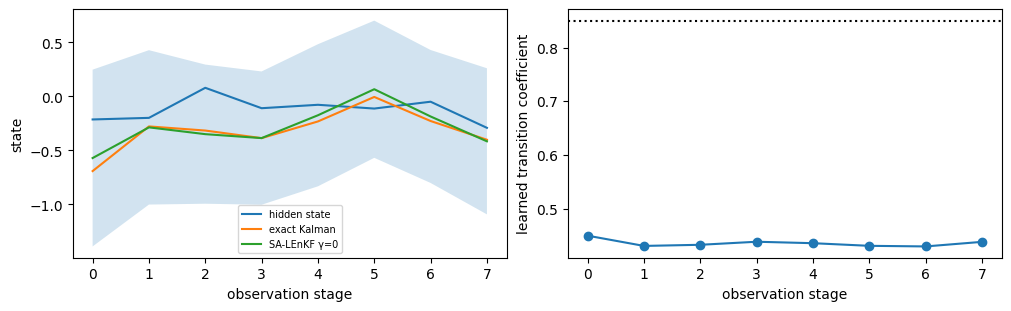

In [3]:
# State filtering at known theta vs exact Kalman, then separate unknown-theta learning.
model=LinearGaussianStateSpace(device=device,dtype=dtype)
states,observations=model.simulate(8,seed=12); kalman=model.kalman_filter(observations)
prior=lambda z:.5*z.square().sum(-1)
init=torch.randn((32,1),device=device,dtype=dtype,generator=gen(10))
def make_filter(theta,gamma,offset):
    return SALEnKF(lambda z,t:z*t[0],model.Q,model.H,model.R,prior,init,tensor([theta]),epsilon=.035,gamma=gamma,inner_steps=35 if quick else 120,burnin=15 if quick else 50,generator=gen(offset))
known=make_filter(.85,0.,11); learned=make_filter(.45,.0007,12)
filtered=[]; variances=[]; learned_theta=[]
for obs in observations:
    r=known.step(obs); filtered.append(r.mean[0]); variances.append(r.covariance[0,0]); learned_theta.append(learned.step(obs).theta[0])
filtered=torch.stack(filtered); variances=torch.stack(variances); learned_theta=torch.stack(learned_theta)
table([dict(experiment='known-parameter filtering',mean_RMSE_vs_Kalman=float((filtered-kalman.means[:,0]).square().mean().sqrt()),variance_MAE_vs_Kalman=float((variances-kalman.covariances[:,0,0]).abs().mean()))]); table([dict(experiment='unknown-parameter SA learning',final_theta=float(learned_theta[-1]),true_theta=.85)])
fig,ax=plt.subplots(1,2,figsize=(10,3),layout='constrained'); times=range(len(states))
ax[0].plot(times,cpu(states[:,0]),label='hidden state'); ax[0].plot(times,cpu(kalman.means[:,0]),label='exact Kalman'); ax[0].plot(times,cpu(filtered),label='SA-LEnKF γ=0')
ax[0].fill_between(times,cpu(filtered-2*variances.sqrt()),cpu(filtered+2*variances.sqrt()),alpha=.2); ax[0].legend(fontsize=7); ax[0].set(xlabel='observation stage',ylabel='state')
ax[1].plot(times,cpu(learned_theta),'o-'); ax[1].axhline(.85,color='k',ls=':'); ax[1].set(xlabel='observation stage',ylabel='learned transition coefficient'); plt.show()

Kalman is an independent exact reference for the **known-parameter** linear Gaussian filter. SA-LEnKF uses finite inner samples and backward pools. The unknown-parameter curve is an online point-estimation example over only eight observations; it need not converge to the generating coefficient and is not a parameter posterior.

| reference | mean_difference | boundary_mass | acceptance |
|---|---|---|---|
| resolution 100→150 | 6.754e-13 | 2.086e-11 | — |
| bounds ±2→±2.5 | 3.14e-11 | 5.807e-17 | — |
| MALA vs fine quadrature | 0.0007189 | — | 0.8013 |

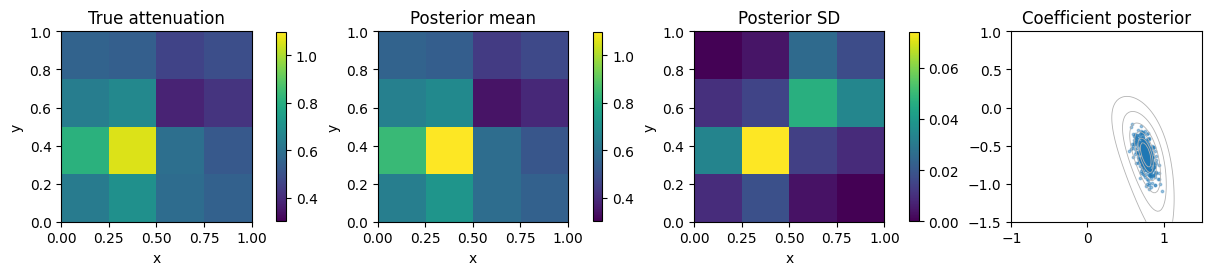

Field shape: (4, 4) observations: 32 retained draws: 6400


In [4]:
# Nonlinear spatial transmission inverse: y = exp(-A exp(x)) + noise.
spatial=NonlinearTomography2D(grid_shape=(4,4),seed=4,device=device,dtype=dtype)
reduced=spatial.reduced(); bounds=((-2.,2.),(-2.,2.))
ref=quadrature_2d(reduced,bounds,resolution=100)
ref_fine=quadrature_2d(reduced,bounds,resolution=150)
ref_wide=quadrature_2d(reduced,((-2.5,2.5),(-2.5,2.5)),resolution=150)
m=samplers.MALA(reduced,torch.zeros((64,2),device=device,dtype=dtype),.003,generator=gen(30))
s,trace,_,accept=collect(m,650 if quick else 2000,250 if quick else 800,4)
if accept < .05: raise RuntimeError('Spatial MALA is stuck; reduce step size before interpreting uncertainty')
fields=reduced.field(s); mean_field=fields.mean(0); sd_field=fields.std(0)
table([dict(reference='resolution 100→150',mean_difference=float((ref.mean-ref_fine.mean).norm()),boundary_mass=float(ref_fine.boundary_mass)),dict(reference='bounds ±2→±2.5',mean_difference=float((ref_fine.mean-ref_wide.mean).norm()),boundary_mass=float(ref_wide.boundary_mass)),dict(reference='MALA vs fine quadrature',mean_difference=float((s.mean(0)-ref_fine.mean).norm()),acceptance=accept)])
fig,ax=plt.subplots(1,4,figsize=(12,3),layout='constrained')
for a,z,title in zip(ax[:3],[spatial.field(spatial.truth),mean_field,sd_field],['True attenuation','Posterior mean','Posterior SD']):
    im=a.imshow(cpu(z),origin='lower',extent=[0,1,0,1],vmin=0 if title=='Posterior SD' else .3,vmax=None if title=='Posterior SD' else 1.1); a.set_title(title); a.set(xlabel='x',ylabel='y'); fig.colorbar(im,ax=a,shrink=.65)
contour(ax[3],reduced,(-1,1.5,-1.5,1)); ax[3].scatter(*cpu(s[::15]).T,s=3,alpha=.4); ax[3].set_title('Coefficient posterior')
fig.savefig(assets/'spatial-uncertainty.png',dpi=130); plt.show()
print('Field shape:',tuple(mean_field.shape),'observations:',len(spatial.observations),'retained draws:',len(s))

Ray/cell intersection lengths define the sparse spatial forward operator. The reduced model has two smooth inclusion coefficients with its own explicit Gaussian prior; it is not a marginal of the full-grid independent prior. Posterior mean/SD are computed **after** mapping each draw through exponentiation, rather than exponentiating a mean coefficient. Quadrature is conditional on finite bounds; boundary mass is a diagnostic, not an omitted-tail bound.